<a href="https://colab.research.google.com/github/yedabird/Pytorch-Tutorial-Youtube/blob/main/MNIST_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
# convert MNIST Image Files into a Tensor of 4-dimension (# of iamges, height, width, channel)
transform = transforms.ToTensor()

train_data = datasets.MNIST(root='/cnn_data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='/cnn_data', train=False, download=True, transform=transform)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 494kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.64MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


In [3]:
train_data

Dataset MNIST
    Number of datapoints: 60000
    Root location: /cnn_data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [4]:
test_data

Dataset MNIST
    Number of datapoints: 10000
    Root location: /cnn_data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [5]:
# create a small batch size fo images ...let's say 10

train_loader = DataLoader(train_data, batch_size=10, shuffle=True)
test_loader = DataLoader(test_data, batch_size=10, shuffle=False)

In [6]:
# Define CNN model ( 2 convolutional layers)
conv1 = nn.Conv2d(1,6,3,1) # in_channel, out_channel, kernel_size, stride
conv2 = nn.Conv2d(6,16,3,1)

In [7]:
# grab 1 MNIST record/image
for i, (X_train, y_train) in enumerate(train_data):
    break

In [8]:
X_train.shape # 1 image, 28 by 28

torch.Size([1, 28, 28])

In [9]:
X_train

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [10]:
x=X_train.view(1,1,28,28)

In [11]:
# perform the first convolution

x = F.relu(conv1(x))

In [12]:
x

tensor([[[[0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          ...,
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000,  ..., 0.0000, 0.0000, 0.0000]],

         [[0.2112, 0.2112, 0.2112,  ..., 0.2112, 0.2112, 0.2112],
          [0.2112, 0.2112, 0.2112,  ..., 0.2112, 0.2112, 0.2112],
          [0.2112, 0.2112, 0.2112,  ..., 0.2112, 0.2112, 0.2112],
          ...,
          [0.2112, 0.2112, 0.3993,  ..., 0.2112, 0.2112, 0.2112],
          [0.2112, 0.2112, 0.2580,  ..., 0.2112, 0.2112, 0.2112],
          [0.2112, 0.2112, 0.2112,  ..., 0.2112, 0.2112, 0.2112]],

         [[0.1937, 0.1937, 0.1937,  ..., 0.1937, 0.1937, 0.1937],
          [0.1937, 0.1937, 0.1937,  ..., 0.1937, 0.1937, 0.1937],
          [0.1937, 0.1937, 0.1937,  ..., 0

In [13]:
x.shape # 1 single image, 6 is the filters we asked for, 26*26

torch.Size([1, 6, 26, 26])

In [14]:
# pass thru the pooling layer

x=F.max_pool2d(x,2,2) # kernel 2, stride 2

In [15]:
x.shape # 26/2=13

torch.Size([1, 6, 13, 13])

In [16]:
# do the second convolutional layer

x = F.relu(conv2(x))

In [17]:
x.shape # again, we don't set padding so we lose 2 pixels

torch.Size([1, 16, 11, 11])

In [18]:
# pooling layer
x = F.max_pool2d(x,2,2)

In [19]:
x.shape # 11/2 = 5.5 we have to round down, we can't invent data to run up

torch.Size([1, 16, 5, 5])

In [20]:
((28-2)/2 -2 ) /2

5.5

In [31]:
class ConvolutionalNetworkd(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(1,6,3,1)
    self.conv2 = nn.Conv2d(6,16,3,1)
    # fully conected layer
    self.fc1 = nn.Linear(5*5*16, 120)
    self.fc2 = nn.Linear(120,84)
    self.fc3 = nn.Linear(84,10)

  def forward(self, x):
    x = F.relu(self.conv1(x))
    x = F.max_pool2d(x,2,2) # 2 by 2 kernal and stride 2
    # second pass
    x = F.relu(self.conv2(x))
    x = F.max_pool2d(x,2,2)
    # reshape for fully connected layer
    x = x.view(-1, 16*5*5) # negative -1 so we can vary the batch size

    #fully connected layers
    x = F.relu(self.fc1(x))
    x = F.relu(self.fc2(x))
    x = self.fc3(x)
    return F.log_softmax(x, dim=1)

In [32]:
# create an instance of our model
torch.manual_seed(41)
model = ConvolutionalNetworkd()
model

ConvolutionalNetworkd(
  (conv1): Conv2d(1, 6, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(6, 16, kernel_size=(3, 3), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (fc3): Linear(in_features=84, out_features=10, bias=True)
)

In [33]:
# loss function optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [34]:
import time
start_time = time.time()

epochs=5
train_losses = []
test_losses = []
train_correct = []
test_correct = []

for i in range(epochs):
  trn_corr = 0
  tst_corr = 0
  #training
  for b, (X_train, y_train) in enumerate(train_loader):
    b+=1

    y_pred = model(X_train)
    loss = criterion(y_pred, y_train)

    predicted = torch.max(y_pred.data, 1)[1]
    batch_corr = (predicted == y_train).sum()

    trn_corr += batch_corr

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if b%600 == 0:
      print(f'epoch: {i}  batch: {b}  loss: {loss.item()}')

  train_losses.append(loss)
  train_correct.append(trn_corr)
  #testing
  with torch.no_grad():
    for b, (X_test, y_test) in enumerate(test_loader):
      y_val = model(X_test)
      predicted = torch.max(y_val.data, 1)[1]
      tst_corr += (predicted == y_test).sum()

  loss = criterion(y_val, y_test)
  test_losses.append(loss)
  test_correct.append(tst_corr)





current_time = time.time()
elapsed = current_time - start_time
print(f"Training time: {elapsed/60:.4f} minutes")
#

epoch: 0  batch: 600  loss: 0.1623610556125641
epoch: 0  batch: 1200  loss: 0.1502392590045929
epoch: 0  batch: 1800  loss: 0.4744560718536377
epoch: 0  batch: 2400  loss: 0.14238706231117249
epoch: 0  batch: 3000  loss: 0.007758188061416149
epoch: 0  batch: 3600  loss: 0.3836284875869751
epoch: 0  batch: 4200  loss: 0.0038223876617848873
epoch: 0  batch: 4800  loss: 0.0021286322735249996
epoch: 0  batch: 5400  loss: 0.0569545142352581
epoch: 0  batch: 6000  loss: 0.00038789428072050214
epoch: 1  batch: 600  loss: 0.005851339548826218
epoch: 1  batch: 1200  loss: 0.3855525553226471
epoch: 1  batch: 1800  loss: 0.004819948226213455
epoch: 1  batch: 2400  loss: 0.003216963727027178
epoch: 1  batch: 3000  loss: 0.0332382395863533
epoch: 1  batch: 3600  loss: 0.5372857451438904
epoch: 1  batch: 4200  loss: 0.04561494290828705
epoch: 1  batch: 4800  loss: 0.0007510822033509612
epoch: 1  batch: 5400  loss: 0.0001173773780465126
epoch: 1  batch: 6000  loss: 0.14201366901397705
epoch: 2  batch

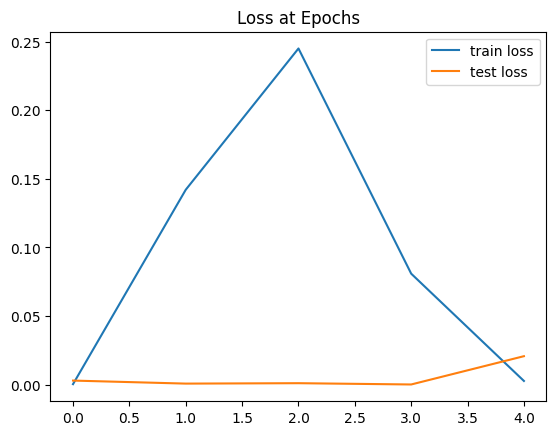

In [42]:
train_loss = [t.item() for t in train_losses]
train_corr = [t.item()/600 for t in train_correct]
test_loss = [t.item() for t in test_losses]
test_corr = [t.item()/100 for t in test_correct]
plt.plot(train_loss, label='train loss')
plt.plot(test_loss, label='test loss')
plt.title("Loss at Epochs")
plt.legend()
plt.show()

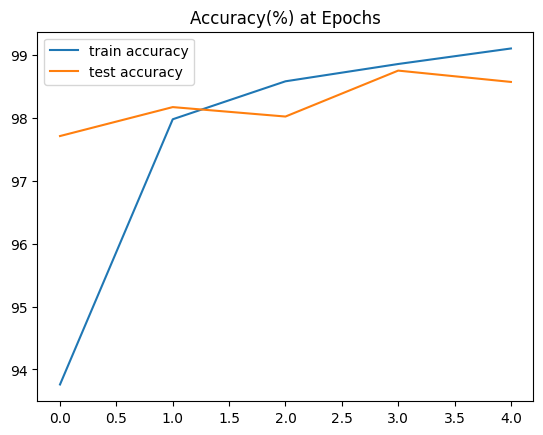

In [45]:
plt.plot(train_corr, label='train accuracy')
plt.plot(test_corr, label='test accuracy')
plt.title("Accuracy(%) at Epochs")
plt.legend()
plt.show()
#

In [46]:
test_load_everything = DataLoader(test_data, batch_size=10000, shuffle=False)

In [47]:
with torch.no_grad():
  correct = 0
  for X_test, y_test in test_load_everything:
    y_val = model(X_test)
    predicted = torch.max(y_val, 1)[1]
    correct += (predicted == y_test).sum()


In [48]:
# Did for correct
correct.item()/len(test_data)*100

98.57000000000001

In [49]:
# Grab an image
test_data[1978] # Tensor with an image in it...at end, it shows the label

(tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 

In [50]:
# Grab just the data
test_data[1978][0]

tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000],
         [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
          0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,

In [51]:
# Reshape it
test_data[1978][0].reshape(28,28)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000

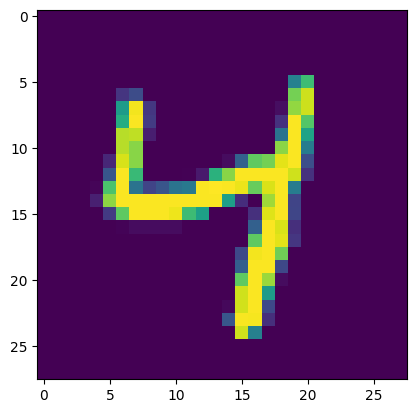

In [52]:
# Show the image
plt.imshow(test_data[1978][0].reshape(28,28))



In [53]:
# Pass the image thru our model
model.eval()
with torch.no_grad():
  new_prediction = model(test_data[1978][0].view(1,1,28,28)) # batch size of 1, 1 color channel, 28x28 image

In [54]:
# Check the new prediction...get probabilities
new_prediction


tensor([[-2.4992e+01, -1.8860e+01, -2.4744e+01, -3.0158e+01, -4.7684e-07,
         -2.1318e+01, -2.2632e+01, -2.0485e+01, -2.1817e+01, -1.4484e+01]])

In [55]:
new_prediction.argmax()


tensor(4)